In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import croak
from croak import marginal_checks as mc
from croak.maths import wlfreq

C = croak.constants.C

In [2]:
omega0 = wlfreq(800e-9)
g = croak.Grid(1024, dt=0.25e-15)
ew = croak.gaussian_pulse(g, 8e-15, phases=[40e-30, 600e-45])   # GDD 40 fs², TOD 600 fs³
truth = croak.TruthPulse.from_spectrum(g, ew, omega0)
true_fwhm = croak.maths.fwhm(g.t, np.abs(g.ifft(ew)) ** 2)
print(f"true temporal FWHM = {true_fwhm / 1e-15:.2f} fs")

delays = np.linspace(-80e-15, 80e-15, 161)
trace = croak.maketrace(g.omega, delays, ew, "thg")

true temporal FWHM = 12.48 fs


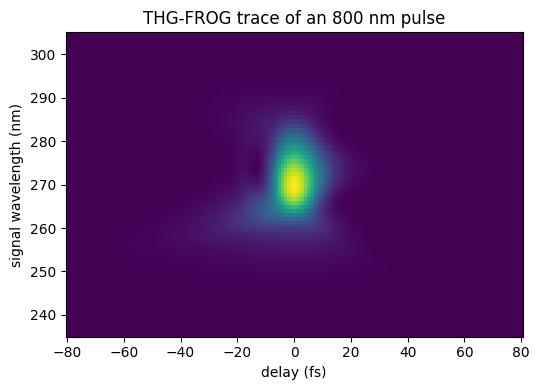

In [3]:
scale = croak.get_interaction("thg").omega0_scale
omega_signal = g.omega + scale * omega0
# The wide synthesis grid reaches below zero absolute frequency; keep the
# physical rows and sort them so the wavelength axis is monotonic.
physical = omega_signal > 0
lam_signal = wlfreq(omega_signal[physical])
order = np.argsort(lam_signal)

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.pcolormesh(delays / 1e-15, lam_signal[order] / 1e-9, trace[physical][order],
              shading="auto")
ax.set_ylim(235, 305)
ax.set_xlabel("delay (fs)")
ax.set_ylabel("signal wavelength (nm)")
ax.set_title("THG-FROG trace of an 800 nm pulse")
fig.tight_layout()

THG, ±40 fs² GDD                 max |ΔT| = 6.2e-15


SD, ±40 fs² GDD                  max |ΔT| = 6.9e-01
THG, ±40 fs² GDD + 600 fs³ TOD   max |ΔT| = 7.0e-01


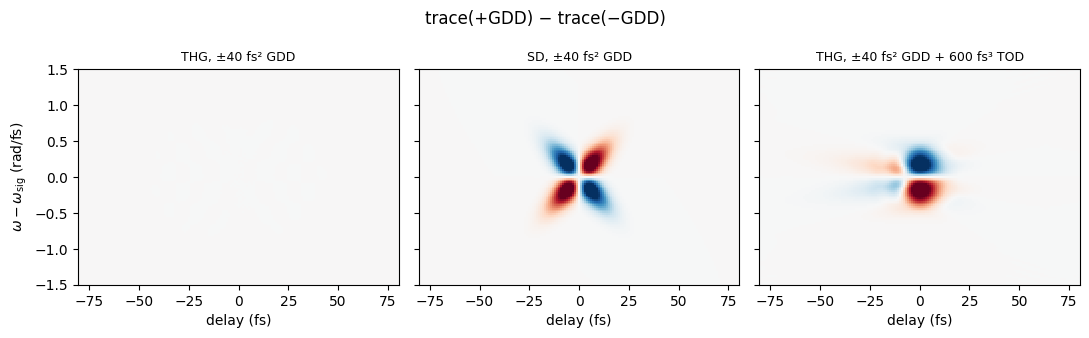

In [4]:
def trace_of(interaction, phases):
    pulse = croak.gaussian_pulse(g, 8e-15, phases=phases)
    return croak.maketrace(g.omega, delays, pulse, interaction)

cases = {
    "THG, ±40 fs² GDD": ("thg", [40e-30], [-40e-30]),
    "SD, ±40 fs² GDD": ("sd", [40e-30], [-40e-30]),
    "THG, ±40 fs² GDD + 600 fs³ TOD": ("thg", [40e-30, 600e-45], [-40e-30, 600e-45]),
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (label, (inter, plus, minus)) in zip(axes, cases.items()):
    diff = trace_of(inter, plus) - trace_of(inter, minus)
    print(f"{label:32s} max |ΔT| = {np.abs(diff).max():.1e}")
    ax.pcolormesh(delays / 1e-15, g.omega / 1e15, diff, cmap="RdBu_r",
                  vmin=-0.5, vmax=0.5, shading="auto")
    ax.set_ylim(-1.5, 1.5)
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("delay (fs)")
axes[0].set_ylabel(r"$\omega - \omega_\mathrm{sig}$ (rad/fs)")
fig.suptitle("trace(+GDD) − trace(−GDD)")
fig.tight_layout()

In [5]:
omega_sig = g.omega + scale * omega0
lam = wlfreq(omega_sig)
order = np.argsort(lam)
lam = lam[order]
meas = croak.preprocess.omega_to_lambda_density(trace[order], lam)
meas /= meas.max()
keep = (lam > 200e-9) & (lam < 360e-9)
lam, meas = lam[keep], meas[keep]
meas = meas + 1e-3 * np.random.default_rng(1).standard_normal(meas.shape)

omega_fund = g.omega + omega0
lam_spec = wlfreq(omega_fund)
order = np.argsort(lam_spec)
lam_spec = lam_spec[order]
Ilam_spec = croak.preprocess.omega_to_lambda_density(np.abs(ew[order]) ** 2, lam_spec)
inside = (lam_spec > 500e-9) & (lam_spec < 1400e-9)
lam_spec, Ilam_spec = lam_spec[inside], Ilam_spec[inside] / Ilam_spec[inside].max()

centroid: measured 269.1 nm, predicted 266.7 nm (soft: True)
width   : measured 220 rad/ps  >  σ_S = 148 rad/ps (rigorous lower bound)


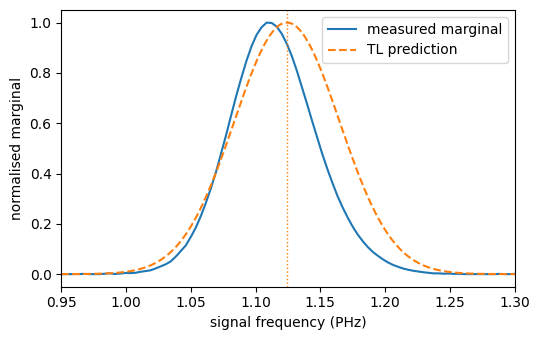

In [6]:
omega_t = wlfreq(lam)
marg_omega = np.clip(meas.sum(axis=1), 0, None) * lam**2      # λ-density -> ω-density

omega_s = wlfreq(lam_spec)
s_omega = Ilam_spec * lam_spec**2
o = np.argsort(omega_s)
omega_u = np.linspace(omega_s.min(), omega_s.max(), 2048)
pred = mc.predicted_marginal(omega_u, np.interp(omega_u, omega_s[o], s_omega[o]), "thg")

c_meas = mc.centroid(omega_t, marg_omega)
w_meas = mc.rms_width(omega_t, marg_omega)
print(f"centroid: measured {wlfreq(c_meas) / 1e-9:.1f} nm, "
      f"predicted {wlfreq(pred.centroid) / 1e-9:.1f} nm (soft: {not pred.centroid_is_hard})")
print(f"width   : measured {w_meas / 1e12:.0f} rad/ps  >  σ_S = "
      f"{pred.width_bracket[0] / 1e12:.0f} rad/ps (rigorous lower bound)")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
o_t = np.argsort(omega_t)
ax.plot(omega_t[o_t] / (2e15 * np.pi), marg_omega[o_t] / marg_omega.max(),
        label="measured marginal")
ax.plot(pred.omega / (2e15 * np.pi), pred.marginal, "--", label="TL prediction")
ax.axvline(pred.centroid / (2e15 * np.pi), color="C1", lw=1, ls=":")
ax.set_xlim(0.95, 1.3)
ax.set_xlabel("signal frequency (PHz)")
ax.set_ylabel("normalised marginal")
ax.legend()
fig.tight_layout()

In [7]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # the taper warning is the point here
    naive = croak.load_and_clean(meas, lam, delays, "thg",
                                 lam_min=700e-9, lam_max=920e-9, input_unit="delay")
print(f"700–920 nm band: the edge taper removes {naive.taper_loss:.0%} of the trace")

700–920 nm band: the edge taper removes 25% of the trace


In [8]:
marg = np.clip(meas.sum(axis=1), 0, None)
edge = np.where(marg > 3e-3 * marg.max())[0]       # above this trace's noise floor
lam_trace_min, lam_trace_max = lam[edge[0]], lam[edge[-1]]
lam_min, lam_max = croak.fundamental_band(lam_trace_min, lam_trace_max, scale)
print(f"trace spans {lam_trace_min / 1e-9:.0f}–{lam_trace_max / 1e-9:.0f} nm "
      f"-> fundamental band {lam_min / 1e-9:.0f}–{lam_max / 1e-9:.0f} nm "
      f"(not {3 * lam_trace_min / 1e-9:.0f}–{3 * lam_trace_max / 1e-9:.0f} nm)")

td = croak.load_and_clean(meas, lam, delays, "thg",
                          lam_min=lam_min, lam_max=lam_max, input_unit="delay",
                          lam_spec=lam_spec, Ilam_spec=Ilam_spec)
print(f"taper loss {td.taper_loss:.2%}; grid {td.grid.n} points, "
      f"dt = {td.grid.dt / 1e-15:.2f} fs")

trace spans 240–300 nm -> fundamental band 600–1200 nm (not 720–900 nm)
taper loss 0.33%; grid 81 points, dt = 4.00 fs


In [9]:
result = croak.retrieve_from_tracedata(td, rng=np.random.default_rng(0))
pr = croak.process_result(result, measured=td.trace)
print(f"FROG error R = {result.error:.2e}")
print(f"FWHM {pr.fwhm_retr / 1e-15:.2f} fs (true {true_fwhm / 1e-15:.2f} fs)")
print(f"GDD {pr.gdd_fs2:.0f} fs² (true 40),  TOD {pr.tod_fs3:.0f} fs³ (true 600)")

FROG error R = 9.26e-04
FWHM 12.50 fs (true 12.48 fs)
GDD 40 fs² (true 40),  TOD 609 fs³ (true 600)


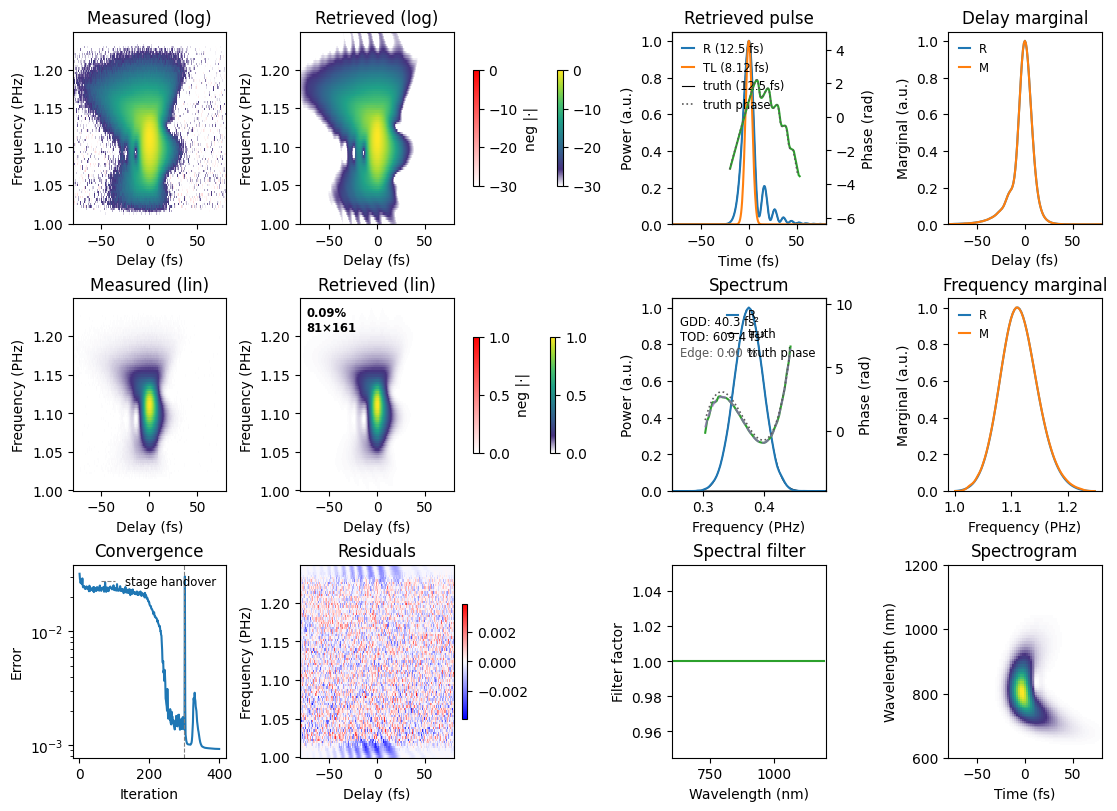

In [10]:
fig = croak.plot_retrieval(result, measured=td.trace, Iomega_meas=td.Iomega,
                           lam_min=td.lam_min, lam_max=td.lam_max,
                           truth=truth, processed=pr)
fig.set_size_inches(11, 8)
fig